# Phase 1 · 03 · Preprocessing

**Goal:** turn the raw abundance table into the feature matrix the paper's random forest was trained on.

**What this notebook shows**
- Why the `unassigned` column is removed.
- The exact feature filter behind the paper's 347 genera, found by testing candidate rules against the paper's own list.
- The normalization the paper uses (log, then standardize), worked through on a three-sample example.
- One place where the paper's setup lets test data influence preprocessing, which we copy on purpose and name.

## Setup

Helpers copied from notebooks 01 and 02.

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

In [2]:
def find_project_root() -> Path:
    """Walk up from the current folder until we find the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("Could not find the project root (no requirements.txt above this folder).")
        folder = folder.parent
    return folder


def load_raw_tables(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return (metadata, relab), both indexed by Sample_ID and in the same row order."""
    raw = root / "data" / "raw"
    metadata = pd.read_csv(raw / "Metadata.all.samples.tsv", sep="\t", index_col="Sample_ID", dtype={"Sample_ID": str})
    genus_by_sample = pd.read_csv(raw / "Relab.all.samples.tsv", sep="\t", index_col=0)
    relab = genus_by_sample.T
    if set(relab.index) != set(metadata.index):
        raise ValueError("The two tables do not contain the same samples.")
    relab = relab.loc[metadata.index]
    return metadata, relab


PROJECT_ROOT = find_project_root()
PROCESSED = PROJECT_ROOT / "data" / "processed"
SHEETS = PROJECT_ROOT / "papers" / "spreadsheets"
FIGURES = PROJECT_ROOT / "results" / "figures"
TABLES = PROJECT_ROOT / "results" / "tables"
NOTEBOOK_PREFIX = "p1_03"
figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{NOTEBOOK_PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))

In [3]:
metadata, relab = load_raw_tables(PROJECT_ROOT)
balanced_samples = pd.read_csv(PROCESSED / "balanced_samples.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
print("all samples:", relab.shape, "  balanced samples:", len(balanced_samples))

all samples: (8330, 3804)   balanced samples: 5966


## 1. Remove `unassigned`

`unassigned` is the share of each sample's DNA that could not be matched to any known genus. It is a leftover, not a bacterium, so it is not a meaningful feature. The paper's scripts remove it (`filter(genus != 'unassigned')`), and SIAMCAT, the R package they use, drops it too through a fixed list of "unmapped" names. We use the same list.

In [4]:
UNMAPPED_NAMES = [
    "UNMAPPED", "-1", "X.1", "unmapped", "Unclassified", "Unassigned",
    "UNCLASSIFIED", "unclassified", "UNASSIGNED", "unassigned",
]

relab = relab.drop(columns=[name for name in UNMAPPED_NAMES if name in relab.columns])
print(f"{relab.shape[1]:,} genera left")

3,803 genera left


## 2. Which genera does the paper keep?

The paper reports 347 genera, and its Table S3 lists them by name. Its Methods say features were kept if "present in 10% of all samples". That leaves two details open: *which* samples (all 8,330, or only the 6,779 CRC and control samples), and whether the cut is "more than" or "at least" 10%. SIAMCAT uses "more than".

Instead of guessing, we try all four combinations and compare each result with the paper's list.

In [5]:
def prevalence_filter(relab: pd.DataFrame, cutoff: float = 0.1) -> list[str]:
    """Genera that are non-zero in more than `cutoff` of the samples, without unmapped names (SIAMCAT's rule)."""
    prevalence = (relab > 0).mean()
    kept = prevalence[prevalence > cutoff].index
    return [genus for genus in kept if genus not in UNMAPPED_NAMES]

In [6]:
s3_genera = set(pd.read_excel(SHEETS / "mmc3.xlsx", sheet_name="ST3C")["Genera"].dropna())
print(f"Table S3 lists {len(s3_genera)} genera")

crc_ctr_ids = metadata.index[metadata["Condition"].isin(["CRC", "CTR"])]
candidate_rules = {
    "> 10% of all 8,330 samples": (relab, "more"),
    "> 10% of the 6,779 CRC and control samples": (relab.loc[crc_ctr_ids], "more"),
    ">= 10% of all 8,330 samples": (relab, "at least"),
    ">= 10% of the 6,779 CRC and control samples": (relab.loc[crc_ctr_ids], "at least"),
}

rows = []
rule_genera = {}
for rule, (samples, comparison) in candidate_rules.items():
    prevalence = (samples > 0).mean()
    kept = set(prevalence[prevalence > 0.1].index if comparison == "more" else prevalence[prevalence >= 0.1].index)
    rule_genera[rule] = kept
    rows.append({
        "rule": rule,
        "n_genera": len(kept),
        "n_in_s3": len(kept & s3_genera),
        "n_missing": len(s3_genera - kept),
        "n_extra": len(kept - s3_genera),
    })

rule_table = pd.DataFrame(rows)
TABLES.mkdir(parents=True, exist_ok=True)
rule_table.to_csv(TABLES / "genus_filter_rules.csv", index=False)
rule_table

Table S3 lists 347 genera


,rule,n_genera,n_in_s3,n_missing,n_extra
0,"> 10% of all 8,330 samples",347,347,0,0
1,"> 10% of the 6,779 CRC and control samples",337,332,15,5
2,">= 10% of all 8,330 samples",348,347,0,1
3,">= 10% of the 6,779 CRC and control samples",337,332,15,5


In [7]:
exact_matches = rule_table.loc[(rule_table["n_missing"] == 0) & (rule_table["n_extra"] == 0), "rule"]
best_rule = exact_matches.iloc[0] if len(exact_matches) else rule_table.sort_values(["n_missing", "n_extra"]).iloc[0]["rule"]
best_rule_genera = rule_genera[best_rule]
print("Rule that reproduces the paper's list:" if len(exact_matches) else "No exact match. Closest rule:", best_rule)

Rule that reproduces the paper's list: > 10% of all 8,330 samples


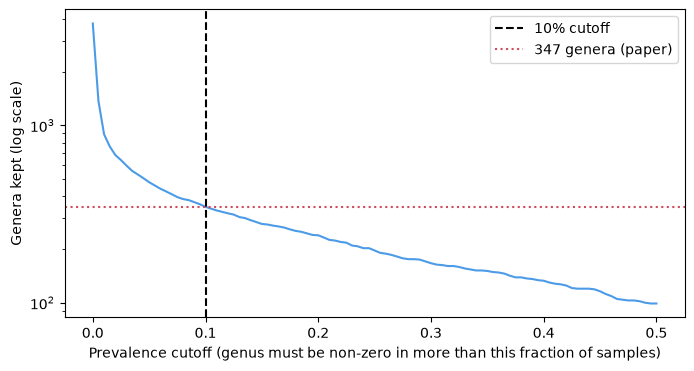

**Figure 1.** Over all 8,330 samples, a 5% cutoff would keep 478 genera, the paper's 10% cutoff keeps 347, and 20% keeps 240. With no cutoff there are 3,803 genera.

In [8]:
cutoffs = np.linspace(0, 0.5, 101)
all_prevalence = (relab > 0).mean()
genera_kept = [(all_prevalence > cutoff).sum() for cutoff in cutoffs]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cutoffs, genera_kept, color="#4C9BE8")
ax.axvline(0.10, color="black", linestyle="--", label="10% cutoff")
ax.axhline(347, color="#D1495B", linestyle=":", label="347 genera (paper)")
ax.set_yscale("log")
ax.set_xlabel("Prevalence cutoff (genus must be non-zero in more than this fraction of samples)")
ax.set_ylabel("Genera kept (log scale)")
ax.legend()


def kept_at(cutoff: float) -> int:
    return int((all_prevalence > cutoff).sum())


show_figure(
    fig,
    "genera_vs_cutoff",
    f"Over all {len(relab):,} samples, a 5% cutoff would keep {kept_at(0.05)} genera, the paper's 10% cutoff keeps "
    f"{kept_at(0.10)}, and 20% keeps {kept_at(0.20)}. With no cutoff there are {relab.shape[1]:,} genera.",
)

## 3. The random forest uses its own filter

The 347 genera above are the list for the paper's statistical analysis. The random forest script (`train_model_rf` in the authors' `utils.R`) applies the same rule again, but only to the samples it trains on, here the 5,966 balanced samples. A different set of samples can give a slightly different list.

In [9]:
relab_balanced = relab.loc[balanced_samples.index]
forest_genera = prevalence_filter(relab_balanced)
print(f"The forest's filter keeps {len(forest_genera)} genera on the balanced samples.")
print(f"{len(set(forest_genera) & s3_genera)} of them are in the paper's list of 347.")

The forest's filter keeps 333 genera on the balanced samples.
328 of them are in the paper's list of 347.


## 4. Normalization: log, then standardize

Two problems with raw shares:
- They span many orders of magnitude. One genus might be 0.3 of a sample, another 0.00001. A logarithm puts them on a comparable scale.
- `log(0)` is undefined, so a tiny pseudocount (`1e-5`) is added first. Every zero becomes `log10(1e-5) = -5`.

Then each genus is **standardized**: subtract its mean, divide by its standard deviation, so every feature is centered on 0 with a similar spread. The paper's tool (SIAMCAT, `log.std`) adds one detail. It divides by *standard deviation + q*, where q is the 10th percentile of all genera's standard deviations. This keeps genera that barely vary from being blown up by a division by a number close to zero.

Normalizing has two steps, and we keep them separate:
- **fit** learns the means and standard deviations from some data,
- **apply** uses those learned numbers on any data.

Keeping them separate matters in notebook 2A/02, where we fit on training studies and apply to a held-out study.

In [10]:
@dataclass
class LogStdParams:
    mean: pd.Series
    adjusted_sd: pd.Series


def fit_log_std(relab: pd.DataFrame, pseudocount: float = 1e-5, sd_quantile: float = 0.1) -> LogStdParams:
    """Learn each genus's mean and adjusted standard deviation on the log scale (SIAMCAT's log.std)."""
    logged = np.log10(relab + pseudocount)
    sd = logged.std(ddof=1)
    q = np.quantile(sd, sd_quantile)
    assert q > 0, "the 10th percentile of standard deviations must be positive"
    return LogStdParams(mean=logged.mean(), adjusted_sd=sd + q)


def apply_log_std(relab: pd.DataFrame, params: LogStdParams, pseudocount: float = 1e-5) -> pd.DataFrame:
    """Log-transform and standardize with already learned parameters."""
    logged = np.log10(relab + pseudocount)
    return (logged - params.mean) / params.adjusted_sd

A three-sample example, small enough to follow by hand. Genus `g1` is 0, 0.5 and 0.2 in the three samples.

In [11]:
tiny = pd.DataFrame({"g1": [0.0, 0.5, 0.2], "g2": [0.1, 0.1, 0.0]}, index=["sample_1", "sample_2", "sample_3"])
tiny_params = fit_log_std(tiny)

print("after log10(x + 1e-5):")
print(np.log10(tiny + 1e-5).round(3), "\n")
print("learned mean:", tiny_params.mean.round(3).to_dict())
print("learned adjusted sd:", tiny_params.adjusted_sd.round(3).to_dict(), "\n")
print("normalized:")
print(apply_log_std(tiny, tiny_params).round(3))

after log10(x + 1e-5):
             g1   g2
sample_1 -5.000 -1.0
sample_2 -0.301 -1.0
sample_3 -0.699 -5.0 

learned mean: {'g1': -2.0, 'g2': -2.333}
learned adjusted sd: {'g1': 4.945, 'g2': 4.648} 

normalized:
             g1     g2
sample_1 -0.607  0.287
sample_2  0.344  0.287
sample_3  0.263 -0.574


## 5. The unified feature matrix, and a leak we copy on purpose

For the paper's unified model, `train_model_rf` filters and normalizes **all 5,966 samples at once, before** cross-validation splits them into training and test folds. So the test folds help decide which genera are kept and what the means and standard deviations are. That is a small information leak from test to training data.

We copy it, because the goal of Phase 2A is to reproduce the paper. Phase 2B will redo it properly inside each fold and measure the difference.

In [12]:
unified_params = fit_log_std(relab_balanced[forest_genera])
features_unified = apply_log_std(relab_balanced[forest_genera], unified_params)
print("unified feature matrix:", features_unified.shape)

unified feature matrix: (5966, 333)


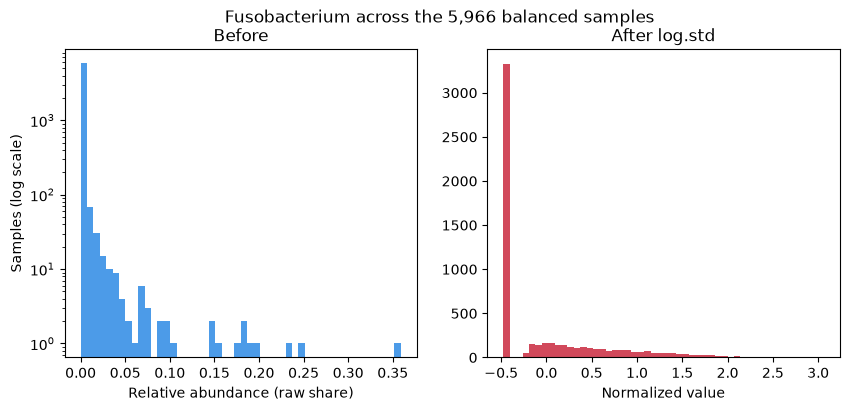

**Figure 2.** Fusobacterium is zero in 56% of the 5,966 samples, and its largest share is 0.359. Before normalizing, almost all samples sit in the first bar. After it, the values run from -0.48 to 3.06 with mean 0.00. All zeros land on the same value, -0.48, the tall bar on the left.

In [13]:
genus = "Fusobacterium"
raw_values = relab_balanced[genus]
normalized_values = features_unified[genus]
zero_share = (raw_values == 0).mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.hist(raw_values, bins=50, color="#4C9BE8")
left.set_yscale("log")
left.set_xlabel("Relative abundance (raw share)")
left.set_ylabel("Samples (log scale)")
left.set_title("Before")
right.hist(normalized_values, bins=50, color="#D1495B")
right.set_xlabel("Normalized value")
right.set_title("After log.std")
fig.suptitle(f"{genus} across the {len(relab_balanced):,} balanced samples")

show_figure(
    fig,
    "normalization_example",
    f"{genus} is zero in {zero_share:.0%} of the {len(raw_values):,} samples, and its largest share is {raw_values.max():.3f}. "
    f"Before normalizing, almost all samples sit in the first bar. After it, the values run from {normalized_values.min():.2f} "
    f"to {normalized_values.max():.2f} with mean {round(normalized_values.mean(), 2) + 0.0:.2f}. All zeros land on the same value, "
    f"{normalized_values[raw_values == 0].iloc[0]:.2f}, the tall bar on the left.",
)

## 6. Save the outputs

- `relab_balanced.parquet`: raw shares for the 5,966 samples and all genera except `unassigned`. Notebook 2A/02 filters and normalizes this per training split.
- `labels.csv`: for each sample, its study, sequencing method and label (1 = CRC, 0 = control), in the same row order.
- `features_unified.parquet`: the filtered and normalized matrix for the unified model in notebook 2A/01.

In [14]:
labels = balanced_samples[["Cohort", "Assay"]].copy()
labels["label"] = (balanced_samples["Condition"] == "CRC").astype(int)

relab_balanced.to_parquet(PROCESSED / "relab_balanced.parquet")
labels.to_csv(PROCESSED / "labels.csv")
features_unified.to_parquet(PROCESSED / "features_unified.parquet")
print("Saved relab_balanced.parquet, labels.csv and features_unified.parquet to data/processed/")

Saved relab_balanced.parquet, labels.csv and features_unified.parquet to data/processed/


## 7. Checks

In [15]:
s3_genera = set(pd.read_excel(SHEETS / "mmc3.xlsx", sheet_name="ST3C")["Genera"].dropna())
assert len(s3_genera) == 347
assert set(best_rule_genera) == s3_genera

tiny = pd.DataFrame({"g1": [0.0, 0.5, 0.2], "g2": [0.1, 0.1, 0.0]})
p = fit_log_std(tiny)
z = apply_log_std(tiny, p)
assert np.isfinite(z.to_numpy()).all()
assert np.allclose(z.mean(), 0)

assert relab_balanced.index.equals(labels.index)
assert len(labels) == 5966 and labels["label"].sum() == 2983
assert np.isfinite(features_unified.to_numpy()).all()
assert list(features_unified.columns) == prevalence_filter(relab_balanced)
print("All checks passed.")

All checks passed.


## What we learned

- `unassigned` is a leftover (DNA matched to no genus), not a feature, and is removed. 3,803 genera remain.
- The paper's 347 genera come from one exact rule: keep a genus if it is non-zero in **more than** 10% of **all 8,330** samples. It reproduces Table S3 name for name. The other three readings miss by 1 to 20 genera.
- The random forest filters again on the samples it trains on. On the 5,966 balanced samples that keeps 333 genera, 328 of them in the paper's list. So the unified model sees 333 features, not 347.
- Normalization is log10 with a 1e-5 pseudocount, then standardization with a small floor added to each standard deviation. Fit and apply are kept separate, so that later we can learn on training data only.
- For the unified model, the paper filters and normalizes before splitting into folds, which leaks a little information from test to training data. We copy that here and will fix it in Phase 2B.